# 数据分析
分析 low-light 图像和正常图像的亮度差异

Get L channel done.
 - low_l:    dynamic range = [0.00, 0.44], mean = 0.10
 - normal_l: dynamic range = [0.02, 1.00], mean = 0.44
 - gain_l:   dynamic range = [1.70, 26.50], mean = 8.09
 - low_l clipped pixels: 6.68% (threshold = 0.01)


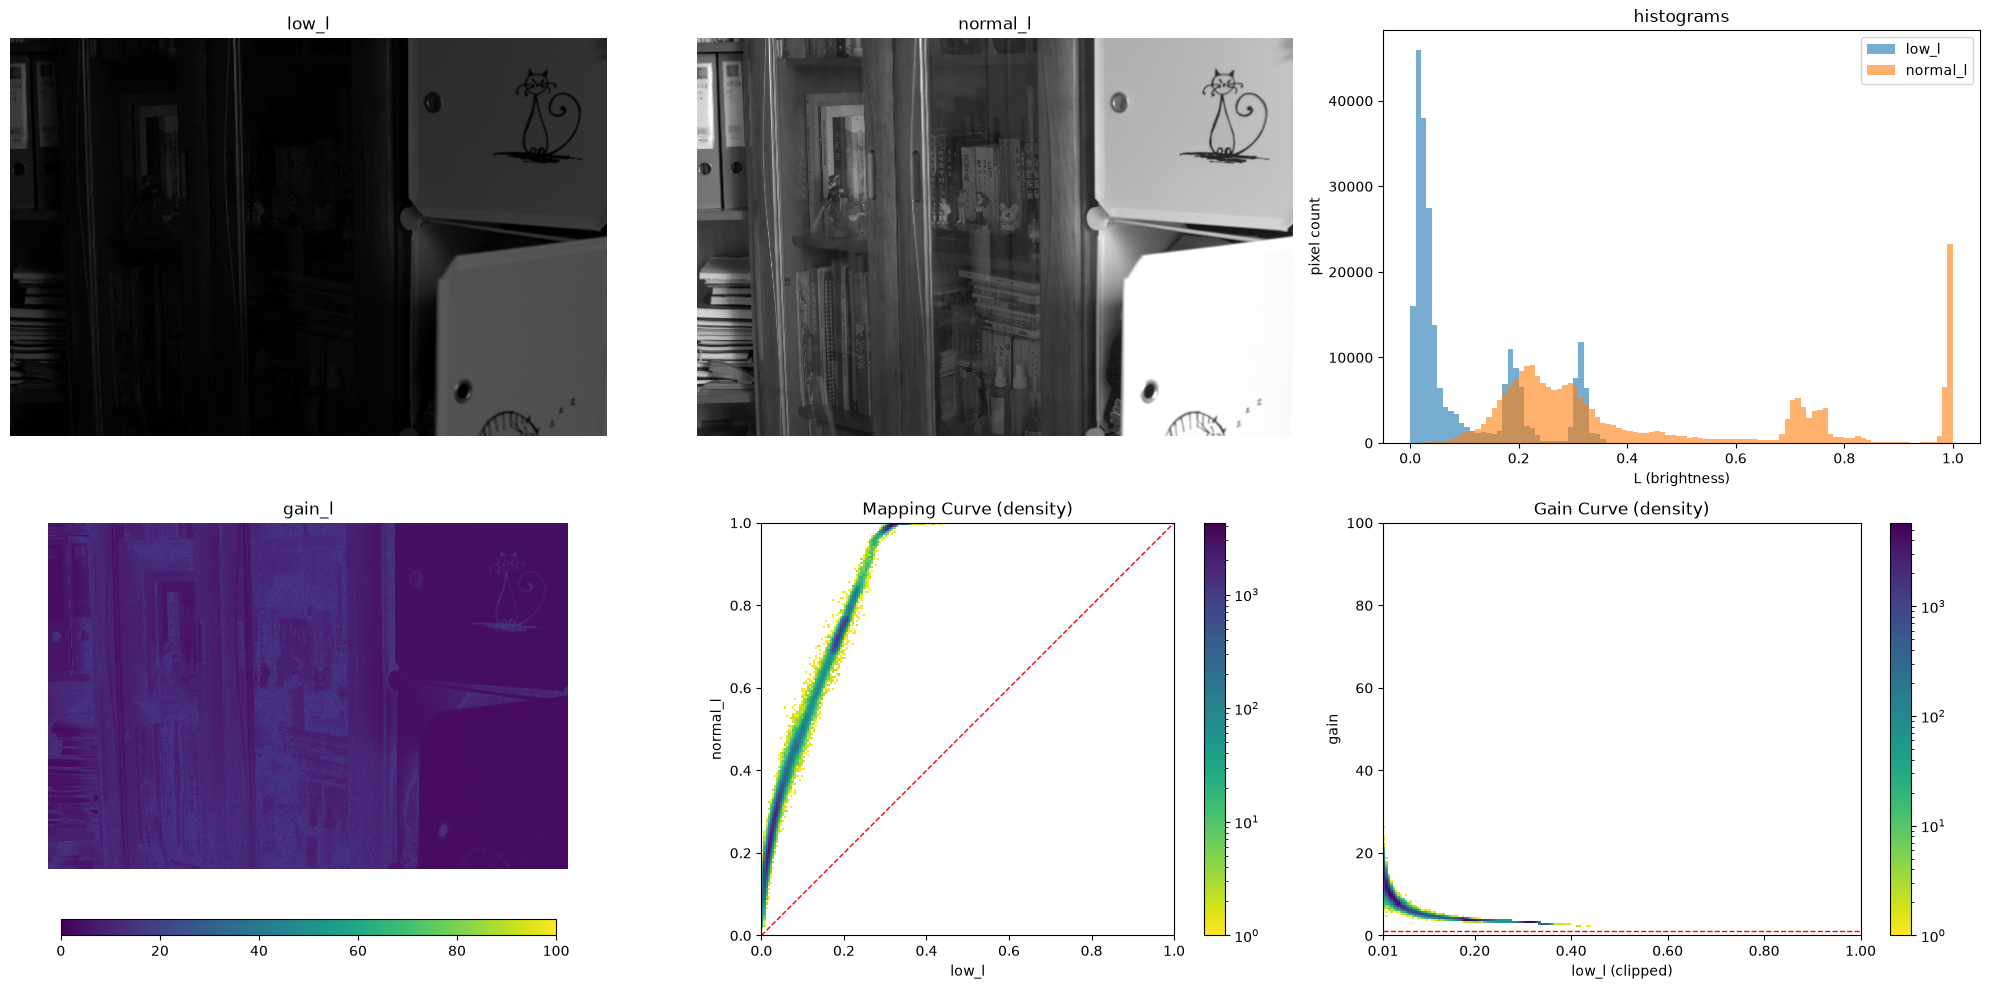

In [2]:
import numpy
import cv2
import matplotlib.colors as mcolors
from lowlight_image_enhance import utils, colorspace
import matplotlib.pyplot as plt

# 0. 参数
LOW_CLIP = 0.01               # low_l 低位截断阈值：低于它的像素无信息，替换为阈值
GAIN_VMAX = 1.0 / LOW_CLIP    # gain_l 统一上限 = 100

# 1. read an image
# 注：物理目录仍为 high/（LOL 数据集原始命名），这里 normal 指"正常光图"
low_bgr_u8 = utils.imread("low/2.png")
normal_bgr_u8 = utils.imread("high/2.png")

# 2. normalize
low_bgr_f32 = utils.normalize(low_bgr_u8)
normal_bgr_f32 = utils.normalize(normal_bgr_u8)

# 3. convert to LCH
low_lch = colorspace.BGR2LCH(low_bgr_f32)
normal_lch = colorspace.BGR2LCH(normal_bgr_f32)

# 4. get L channel + 统一低位截断
low_l = low_lch[:, :, 0]
normal_l = normal_lch[:, :, 0]
low_l_clip = numpy.maximum(low_l, LOW_CLIP) # 无信息像素替换为阈值
delta_l = normal_l - low_l                  # 绝对差值（仅 print 用）
gain_l = normal_l / low_l_clip              # 相对增益，上限统一 = 1/LOW_CLIP
clipped_mask = low_l < LOW_CLIP             # 得到低位截断的像素掩码
percent_clipped = 100.0 * numpy.sum(clipped_mask) / low_l.size  # 计算低位截断像素占比

print("Get L channel done.")
print(f" - low_l:    dynamic range = [{low_l.min():.2f}, {low_l.max():.2f}], mean = {low_l.mean():.2f}")
print(f" - normal_l: dynamic range = [{normal_l.min():.2f}, {normal_l.max():.2f}], mean = {normal_l.mean():.2f}")
print(f" - gain_l:   dynamic range = [{gain_l.min():.2f}, {gain_l.max():.2f}], mean = {gain_l.mean():.2f}")
print(f" - low_l clipped pixels: {percent_clipped:.2f}% (threshold = {LOW_CLIP})")

# 5. plot: 2x3 大图
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# row 0: low_l, normal_l, histograms
axes[0, 0].imshow(low_l, cmap='gray', vmin=0.0, vmax=1.0)
axes[0, 0].set_title("low_l")
axes[0, 0].axis('off')

axes[0, 1].imshow(normal_l, cmap='gray', vmin=0.0, vmax=1.0)
axes[0, 1].set_title("normal_l")
axes[0, 1].axis('off')

axes[0, 2].hist(low_l.ravel(), bins=100, range=(0, 1), alpha=0.6, label='low_l')
axes[0, 2].hist(normal_l.ravel(), bins=100, range=(0, 1), alpha=0.6, label='normal_l')
axes[0, 2].set_xlabel('L (brightness)')
axes[0, 2].set_ylabel('pixel count')
axes[0, 2].set_title('histograms')
axes[0, 2].legend()

# row 1: gain_l, Mapping Curve (density), Gain Curve (density)
im = axes[1, 0].imshow(gain_l, cmap='viridis', vmin=0, vmax=GAIN_VMAX)
axes[1, 0].set_title("gain_l")
axes[1, 0].axis('off')
plt.colorbar(im, ax=axes[1, 0], orientation='horizontal',
             fraction=0.04, pad=0.12, aspect=30)  # 色标横放在增益图下方

hb = axes[1, 1].hist2d(low_l.ravel(), normal_l.ravel(),
                       bins=200, range=[[0, 1], [0, 1]],
                       cmap='viridis_r', norm=mcolors.LogNorm())
axes[1, 1].plot([0, 1], [0, 1], 'r--', lw=1)
axes[1, 1].set_xlabel('low_l')
axes[1, 1].set_ylabel('normal_l')
axes[1, 1].set_title('Mapping Curve (density)')
axes[1, 1].set_aspect('equal')
plt.colorbar(hb[3], ax=axes[1, 1])

# Gain Curve (density): x=截断后 low_l, y=增益(线性 0~100), 色标 LogNorm
hb2 = axes[1, 2].hist2d(low_l_clip.ravel(), gain_l.ravel(),
                        bins=200, range=[[LOW_CLIP, 1.0], [0, GAIN_VMAX]],
                        cmap='viridis_r', norm=mcolors.LogNorm())
axes[1, 2].axhline(1.0, color='r', linestyle='--', lw=1)  # gain=1 参考线（无变化）
axes[1, 2].set_xticks([LOW_CLIP, 0.2, 0.4, 0.6, 0.8, 1.0])  # x 轴起点标出截断阈值 0.01
axes[1, 2].set_xlabel('low_l (clipped)')
axes[1, 2].set_ylabel('gain')
axes[1, 2].set_title('Gain Curve (density)')
plt.colorbar(hb2[3], ax=axes[1, 2])

plt.tight_layout()
plt.show()